# alloc_v2 综合 Dashboard

只读 `data/alloc_v2/`，不打网。先刷新：

```bash
./scripts/run_alloc_v2.sh all --start 2018-01-01
```

**口径**：价格/活跃度 ≠ 流入；份额变化 ≠ 净流入；北向净买额仅 `reference_only`；估算必须看 `estimate` 标签。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("../..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from qlib.contrib.data.alloc_v2.paths import default_root
from qlib.contrib.data.alloc_v2.report import dashboard_payload
from qlib.contrib.data.alloc_v2 import plotting as P

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

print("font:", P.configure_cjk_font())
DATA = default_root()
print("root:", DATA)
payload = dashboard_payload(DATA)
standard = payload["standard"]
factors = payload["factors"]
swing = payload["swing"]
print("standard", len(standard), "factors", len(factors))
print("datasets", sorted(standard["dataset"].unique()) if not standard.empty else [])

font: PingFang SC
root: /Users/900game/Desktop/ai/qlib/data/alloc_v2
standard 277642 factors 331296
datasets ['block_trade', 'cn_macro', 'etf_bar', 'etf_nav', 'etf_shares', 'fund_holding', 'fund_scale_snapshot', 'fx_usdcny', 'gold_gld', 'gold_sge', 'hsgt_hold', 'hsgt_net', 'hsgt_turnover', 'idx_global', 'margin', 'sw_industry', 'yield_cn_us']


## 1. 全球跨资产（proxy）

指数与收益率是定价/活跃度，**不是资金流入**。

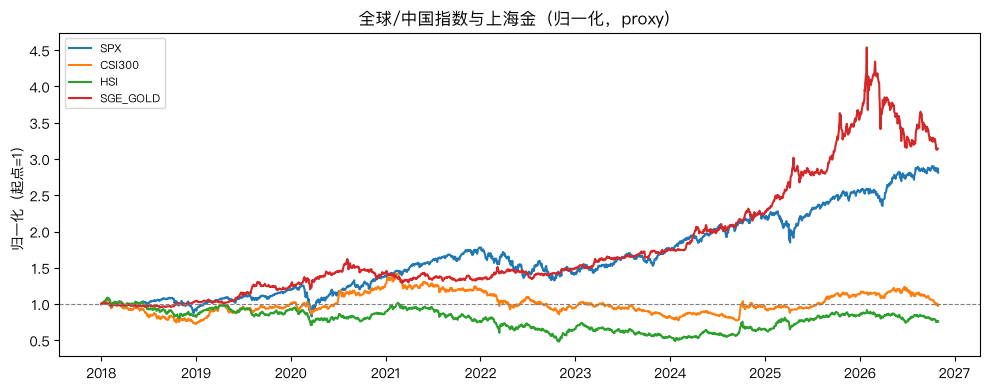

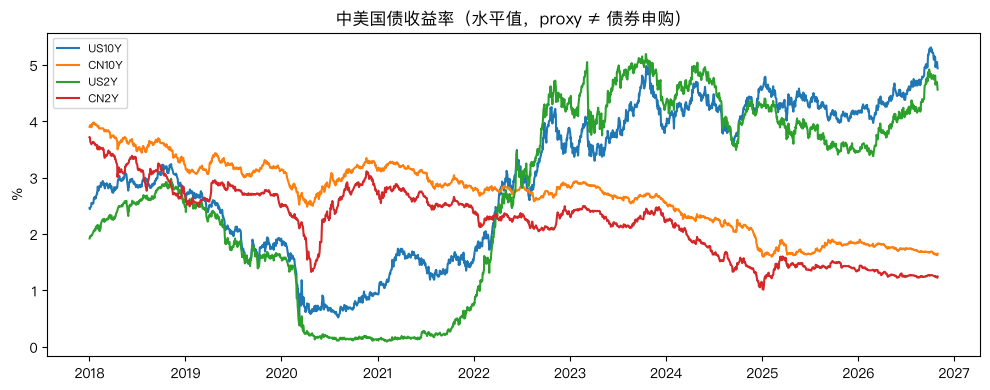

dataset        entity_id  field    
cn_macro       LPR1Y      lpr           493
fx_usdcny      USDCNY     fx           2141
gold_gld       GLD        change       1450
                          tonnes       1450
gold_sge       SGE_GOLD   close        2140
hsgt_hold      NORTH      hold_mcap    2051
               SOUTH      hold_mcap    2026
hsgt_net       NORTH      net_buy      1536
               SOUTH      net_buy      2025
hsgt_turnover  NORTH      amount       1536
               SOUTH      amount       2025
idx_global     CSI300     close        2140
               DJI        close        2220
               HSI        close        2172
               IXIC       close        2220
               N225       close        1000
               SENSEX     close        1000
               SPX        close        2220
               SSE        close        2140
               SX5E       close        1000
dtype: int64

In [2]:
global_map = {
    "SPX": P.series_from_standard(standard, dataset="idx_global", entity_id="SPX", field="close"),
    "CSI300": P.series_from_standard(standard, dataset="idx_global", entity_id="CSI300", field="close"),
    "HSI": P.series_from_standard(standard, dataset="idx_global", entity_id="HSI", field="close"),
    "SGE_GOLD": P.series_from_standard(standard, dataset="gold_sge", entity_id="SGE_GOLD", field="close"),
}
fig = P.plot_normalized(global_map, title="全球/中国指数与上海金（归一化，proxy）")
plt.show()

yield_map = {
    "US10Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="US10Y", field="yield"),
    "CN10Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="CN10Y", field="yield"),
    "US2Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="US2Y", field="yield"),
    "CN2Y": P.series_from_standard(standard, dataset="yield_cn_us", entity_id="CN2Y", field="yield"),
}
fig = P.plot_levels(yield_map, title="中美国债收益率（水平值，proxy ≠ 债券申购）", ylabel="%")
plt.show()
payload["global"].groupby(["dataset", "entity_id", "field"]).size().head(20)

## 2. 北向：成交与持股

核心看成交额与持股市值。**净买额单独一图，仅 reference_only，不作核心因子。**

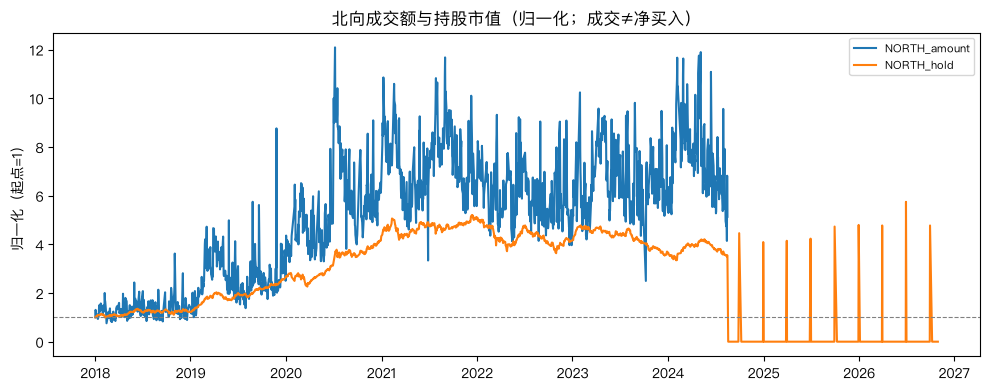

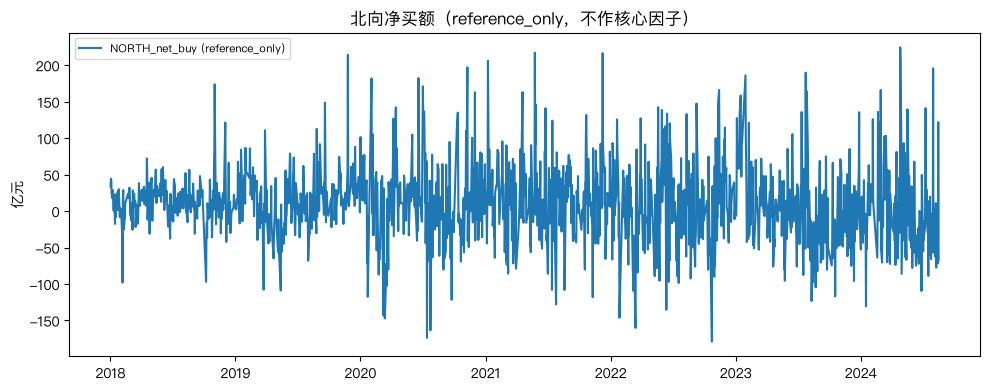

In [3]:
nb_core = {
    "NORTH_amount": P.series_from_standard(standard, dataset="hsgt_turnover", entity_id="NORTH", field="amount"),
    "NORTH_hold": P.series_from_standard(standard, dataset="hsgt_hold", entity_id="NORTH", field="hold_mcap"),
}
fig = P.plot_normalized(nb_core, title="北向成交额与持股市值（归一化；成交≠净买入）")
plt.show()

nb_ref = {
    "NORTH_net_buy (reference_only)": P.series_from_standard(
        standard, dataset="hsgt_net", entity_id="NORTH", field="net_buy"
    ),
}
fig = P.plot_levels(nb_ref, title="北向净买额（reference_only，不作核心因子）", ylabel="亿元")
plt.show()

## 3. 行业配置

`IndustryAllocationScore` 最新截面 Top-N；近 60 日热力。权重均等，样本外再估。

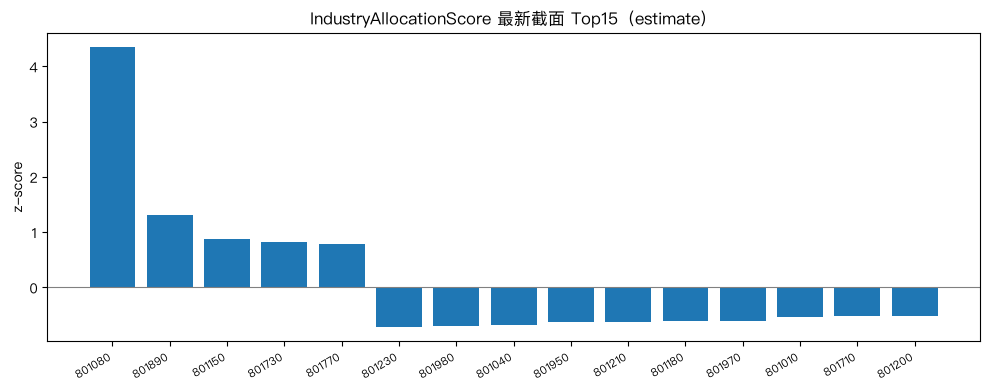

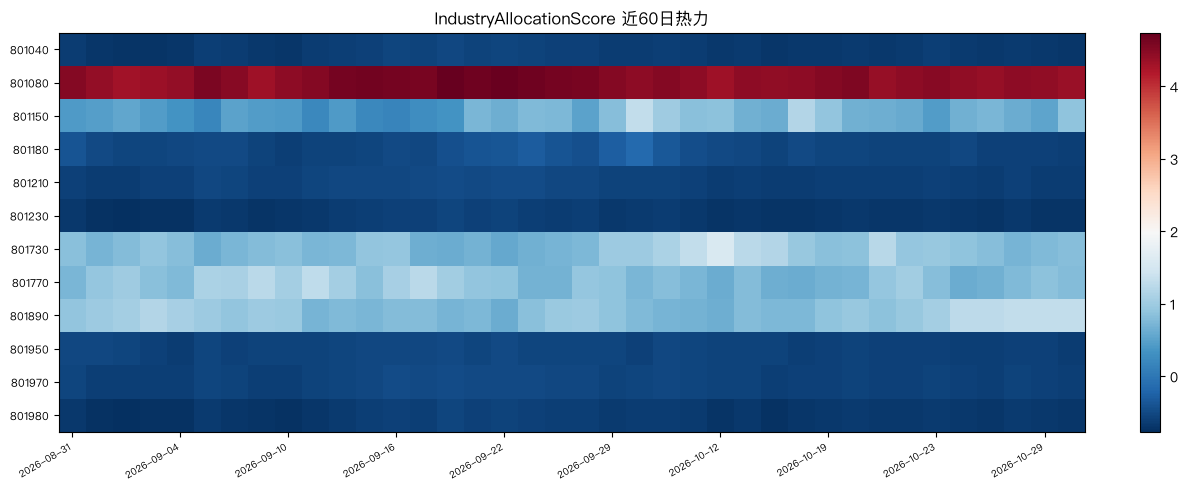

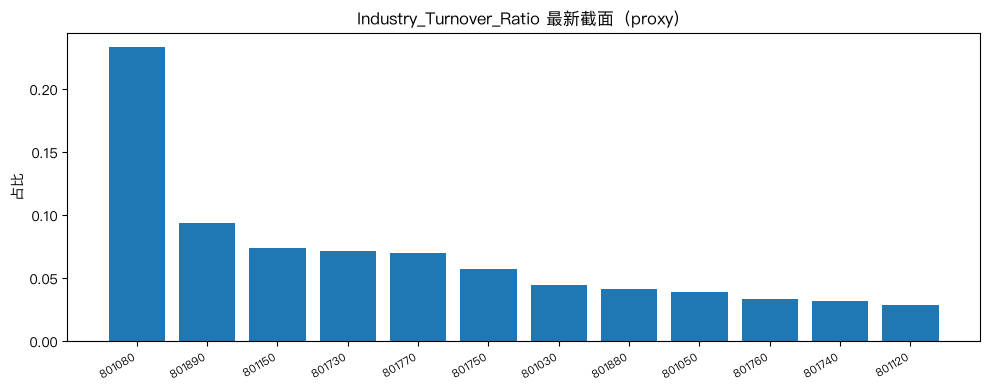

In [4]:
score_top = P.latest_cross_section(factors, "IndustryAllocationScore", top_n=15)
fig = P.plot_bar(
    list(score_top.index.astype(str)),
    list(score_top.values),
    title="IndustryAllocationScore 最新截面 Top15（estimate）",
    ylabel="z-score",
)
plt.show()

fig = P.plot_heatmap_pivot(
    factors,
    "IndustryAllocationScore",
    title="IndustryAllocationScore 近60日热力",
    last_n_days=60,
)
plt.show()

turn_top = P.latest_cross_section(factors, "Industry_Turnover_Ratio", top_n=12)
fig = P.plot_bar(
    list(turn_top.index.astype(str)),
    list(turn_top.values),
    title="Industry_Turnover_Ratio 最新截面（proxy）",
    ylabel="占比",
)
plt.show()

## 4. ETF 三类指标

宽基示例：`510300`。份额变化与 `Estimated_Allocation` 并列；后者是 **estimate**，不是现金净流入。

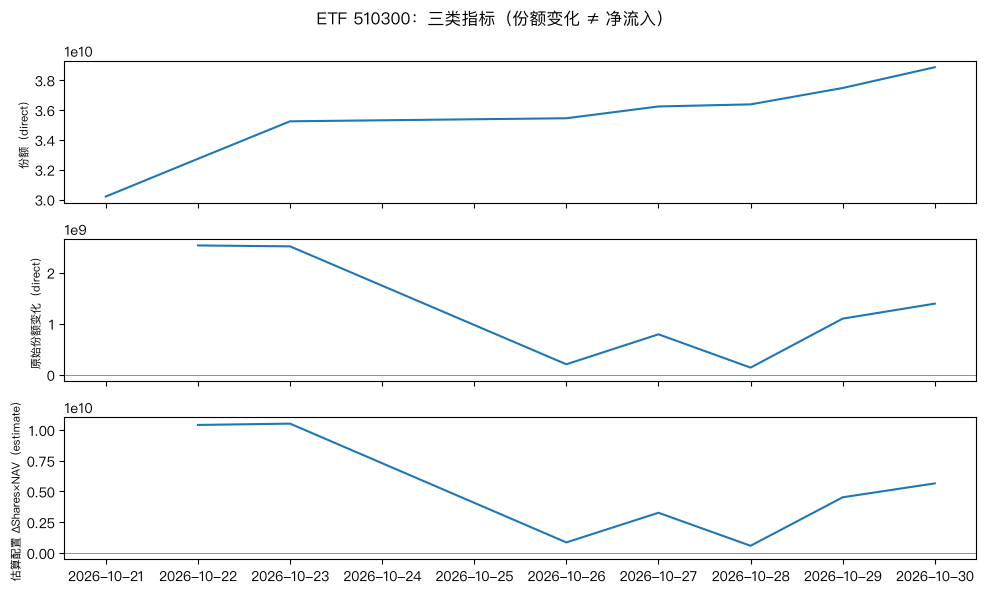

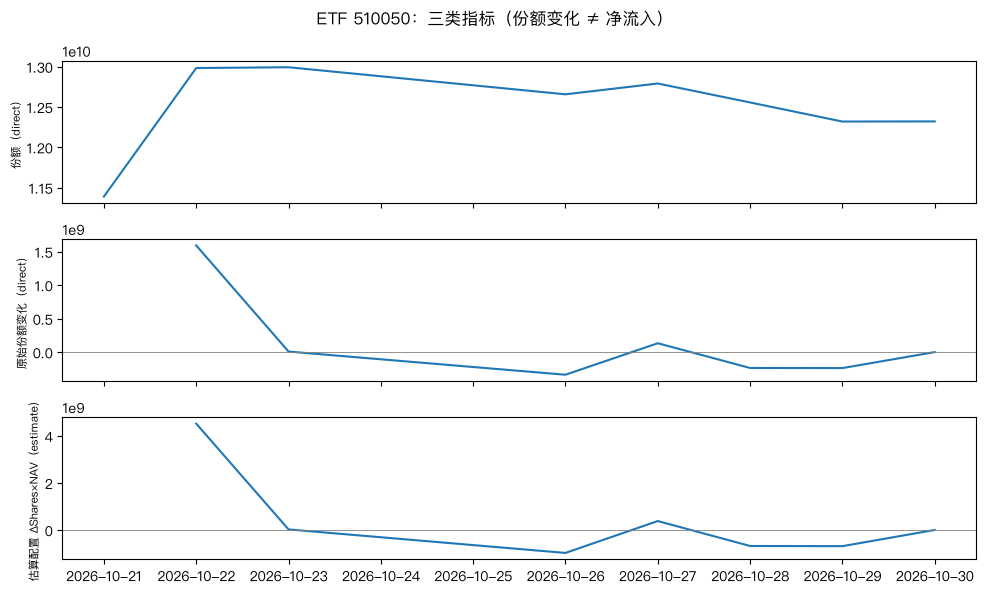

,entity_id,value,quality_flag
3150,159915,0.002305,ok
5290,159922,0.000978,ok
7430,510050,0.000664,share_price_diverge
9570,510300,0.001010,share_price_diverge
11710,510500,-0.000032,share_price_diverge
13850,510880,0.000347,ok
15989,511260,-0.000391,ok
16463,512050,0.000000,share_price_diverge
18602,512100,-0.000598,share_price_diverge
20393,512480,0.001252,share_price_diverge


In [5]:
for code in ("510300", "510050"):
    fig = P.plot_etf_three_metrics(factors, code)
    plt.show()

arb = factors[factors["factor_id"] == "ArbitrageRisk"].copy() if not factors.empty else pd.DataFrame()
if not arb.empty:
    arb["event_date"] = pd.to_datetime(arb["event_date"])
    last = arb["event_date"].max()
    snap = arb[arb["event_date"] == last][["entity_id", "value", "quality_flag"]].head(20)
    display(snap)
else:
    print("无 ArbitrageRisk")

## 5. 信号 S1–S4

三级独立计算再交叉。任意历史日只用当时 `available_at`。

,signal_id,value,statement_kind,components,asof,notes
0,S1,0.0,signal,"{'above_ma': False, 'active': True, 'strength'...",2026-11-01,参数待验；市场层独立计算


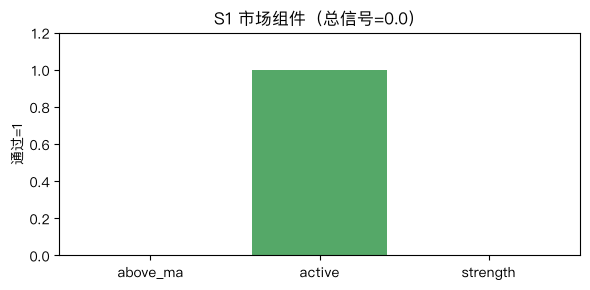

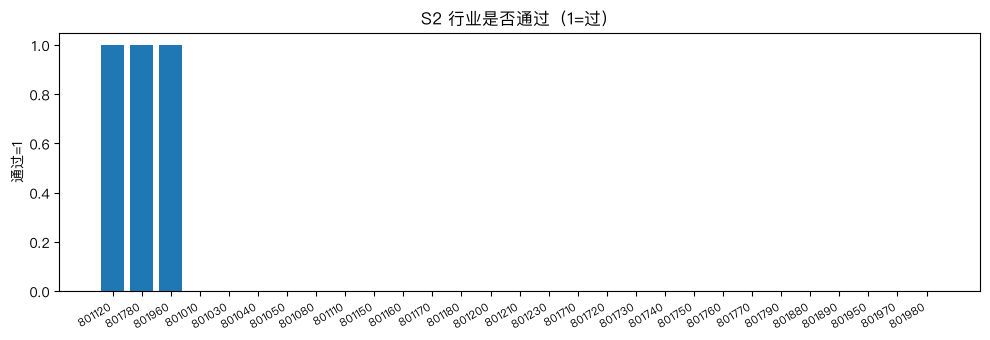

,asof,entity_id,signal_id,value,statement_kind,available_at,quality_flag,notes,version
0,2026-11-01,MARKET,S4,0.0,signal,2026-11-01,ok,S1 failed,signals@v2


,rule_id,signal_id,condition,action,tuned_on
0,S1_ma_break,S1,broad_etf_below_ma60,clear_S4,none
1,S2_flow_fade,S2,IndustryETFFlow20_pct120 < 0.4,drop_industry,none
2,S3_lhb_expire,S3,LHB decay to NA,drop_stock_confirm,none


In [6]:
s1 = swing["S1"]
s2 = swing["S2"]
s4 = swing["S4"]
display(s1)
fig = P.plot_s1_components(s1)
plt.show()
fig = P.plot_s2_pass_bar(s2, title="S2 行业是否通过（1=过）")
plt.show()
display(s4)
display(swing.get("invalidation", pd.DataFrame()))

## 6. 回测记录

失败因子也保留（红柱）。不只留最优组合。

,factor_id,status,failures,version,rank_ic_mean_h5,rank_ic_ir_h5,long_short_mean_h5,long_short_net_h5,rank_ic_mean_h10,rank_ic_ir_h10,long_short_mean_h10,long_short_net_h10,rank_ic_mean_h20,rank_ic_ir_h20,long_short_mean_h20,long_short_net_h20,rank_ic_mean_h40,rank_ic_ir_h40,long_short_mean_h40,long_short_net_h40
0,IndustryAllocationScore,ok,,v2,0.001178,0.003929,-0.000200,-0.002200,0.001804,0.005895,-0.000359,-0.002359,-0.006929,-0.022008,-0.000735,-0.002735,-0.011713,-0.036031,0.000625,-0.001375
1,IndustryETFFlow20,failed,factor_missing,v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Industry_Turnover_Ratio,ok,,v2,0.001178,0.003929,-0.000200,-0.002200,0.001804,0.005895,-0.000359,-0.002359,-0.006929,-0.022008,-0.000735,-0.002735,-0.011713,-0.036031,0.000625,-0.001375
3,Industry_RelRet20,ok,,v2,0.008807,0.026668,0.001531,-0.000469,0.014854,0.045721,0.002316,0.000316,-0.001379,-0.004384,0.001520,-0.000480,-0.030383,-0.096834,0.000380,-0.001620
4,LHB_Institution_Ratio,failed,factor_missing,v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


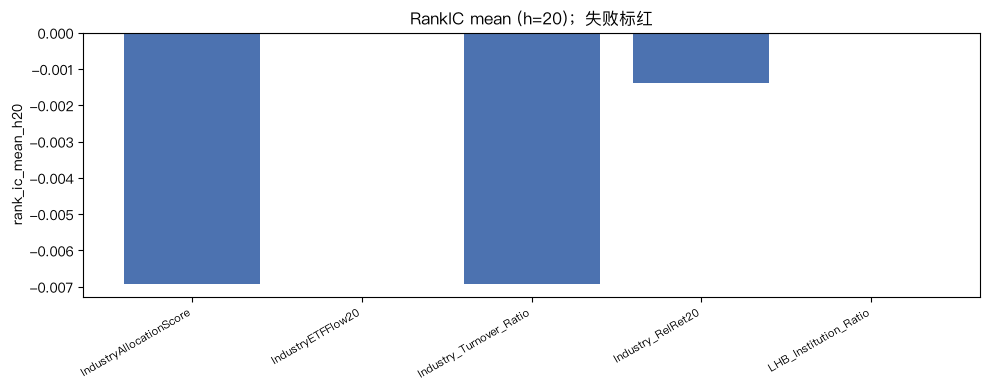

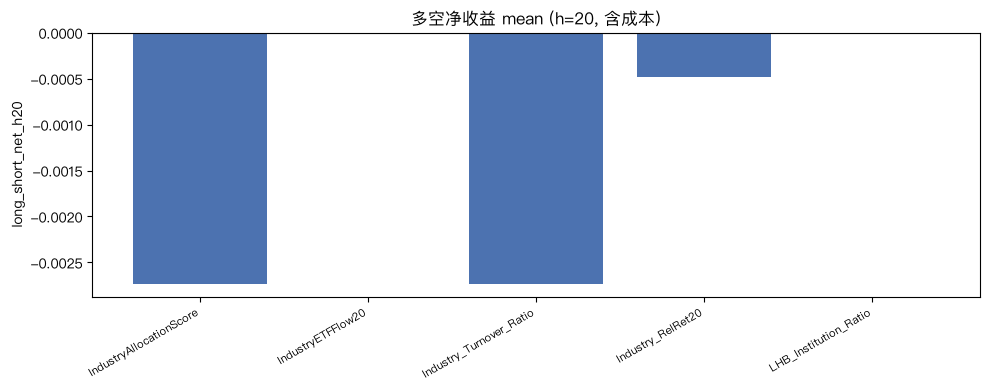

In [7]:
bt = swing["backtest"]
display(bt)
fig = P.plot_backtest_bars(bt, metric="rank_ic_mean_h20", title="RankIC mean (h=20)；失败标红")
plt.show()
fig = P.plot_backtest_bars(bt, metric="long_short_net_h20", title="多空净收益 mean (h=20, 含成本)")
plt.show()